# Imports

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import seaborn as sns
import matplotlib.pyplot as plt

# !pip install ucimlrepo
# from ucimlrepo import fetch_ucirepo

# Class

In [2]:
%load_ext autoreload
%autoreload 2
from Feed_Forward_NN_Class import NN
from Plotting import Plot

In [45]:
# class NN():

#     def __init__(self, X_train: np.ndarray, Y_train: np.ndarray, X_test: np.ndarray, Y_test: np.ndarray, hidden_layer_sizes: np.ndarray):
#         # data should be: rows=features, cols=datapoints
#         self.X_train = X_train
#         self.Y_train = Y_train
#         self.X_test = X_test
#         self.Y_test = Y_test
#         self.one_hot_Y = NN.one_hot(self.Y_train) # shape: [n x c] --> rows=each datapoint , cols=each class possibility (ie. 0, 1, 2)
        
#         self.num_train_data_points = X_train.shape[1]
#         self.num_test_data_points = X_test.shape[1]
#         self.num_data_points = self.num_train_data_points + self.num_test_data_points
#         self.num_hidden_layers = len(hidden_layer_sizes) # one number to indicate # of hidden layers (excluding input & output layers)
#         self.total_num_layers = self.num_hidden_layers + 2
#         self.layer_sizes = np.append(np.append(X_train.shape[0], hidden_layer_sizes), len(np.unique(Y_train))) # array containing every layer size (including input & output layer)
        
#         # self.rng = np.default_rng(seed=42)
#         np.random.seed(42)

#         # self.best_train_accuracy_weights = []
#         # self.best_train_accuracy_biases = []
#         self.best_model_params = {"epoch": -1, "accuracy": -1, "weights": None, "biases": None}

#         self.init_network()

#     def init_network(self):
#         self.weight_matrices = [] # len = L - 1 (L = # all layers)
#         self.bias_vectors = [] # len = L - 1 (L = # all layers)
#         print ("Initializing Network")
#         for index in range(1, self.total_num_layers):
#             n_out = int(self.layer_sizes[index])
#             n_in = int(self.layer_sizes[index-1])
#             # W = np.random.randn(n_out, n_in) # shape = [output x input]
#             W = np.random.randn(n_out, n_in) * np.sqrt(2.0 / n_in) # shape = [output x input]
#             b = np.zeros((n_out, 1))
#             # b = np.full(n_out, 1.0).reshape(n_out, 1)
            
#             self.weight_matrices.append(W)
#             self.bias_vectors.append(b)

#         print ("Network Initialized")

#     def train(self, epochs, learning_rate):
#         self.epochs = epochs
#         self.learning_rate = learning_rate
#         self.accuracies_over_all_epochs = np.array([])
#         self.best_accuracy = -1
        
#         for epoch in range(epochs):
            
#             self.forward_prop()
#             self.back_prop()

#             prediction_accuracy = self._predict_for_training()
    
#             if epoch % 10 == 0:
#                 print ("---------------------------------")
#                 print (f"epoch: {epoch}")
#                 print (f"accuracy: {prediction_accuracy}")
#                 # print ("weights\n", self.weight_matrices, "\n")

#             if prediction_accuracy > self.best_model_params["accuracy"]:
#                 self.best_model_params["epoch"] = epoch
#                 self.best_model_params["accuracy"] = prediction_accuracy
#                 self.best_model_params["weights"] = self.weight_matrices.copy()
#                 self.best_model_params["biases"] = self.bias_vectors.copy()

#         # print ("\n\n", f"epoch # and accuracy of highest accuracy epoch: {np.argmax(self.accuracies_over_all_epochs)}, {self.accuracies_over_all_epochs[np.argmax(self.accuracies_over_all_epochs)]}")
#         print ("\n\n", f"Highest Accuracy:\n\tEpoch # = {self.best_model_params["epoch"]}\n\tAccuracy = {self.best_model_params["accuracy"]}")
        



#     # Core Functions
    
#     def forward_prop(self):

#         # self.weighted_sum_matrices = [self.X_train] # all of the Z matrices (used for backprop)
#         self.weighted_sum_matrices = []
#         self.activations = [self.X_train] # training_set + activations
        
#         # for (index, weight_matrix) in enumerate(self.weight_matrices):
#         for index in range(self.num_hidden_layers):
#             Z = self.weight_matrices[index] @ self.activations[index]
#             Z += self.bias_vectors[index] # Z = linear sum --> (W @ X) + b
#             self.weighted_sum_matrices.append(Z)
#             # A = NN.ReLU(Z) # A = activation of Z
#             A = NN.leaky_ReLU(Z) # A = activation of Z        USING LEAKY NOW
#             self.activations.append(A)

#         # for the output layer
#         Z = self.weight_matrices[-1] @ self.activations[-1]
#         Z += self.bias_vectors[-1]
#         self.weighted_sum_matrices.append(Z)
        
#         output_probability_matrix_wrong_shape = NN.softmax(Z, axis=0) # softmax activation instead of ReLU, shape: rows=features , cols=datapoints
#         self.activations.append(output_probability_matrix_wrong_shape)

#         for i, Z in enumerate(self.weighted_sum_matrices[:-1]):
#             dead_frac = np.mean(Z <= 0)
#             print(f"layer {i}: {dead_frac:.2%} dead neurons")


#         # each matrix in self.forward_prop_inputs has shape: [output_neurons x datapoints]

#     def back_prop(self):
#         # one_hot_Y = NN.one_hot(self.Y_train) # shape: [n x c] --> rows=each datapoint , cols=each class possibility (ie. 0, 1, 2)
#         self.output_probability_matrix = self.activations[-1].T # shape: rows=datapoints , cols=features

#         self.weight_errors = [None] * (self.total_num_layers - 1)
#         self.bias_errors = [None] * (self.total_num_layers - 1)

#         assert self.output_probability_matrix.shape == self.one_hot_Y.shape
#         error_gradient = self.output_probability_matrix - self.one_hot_Y # shape = [n x c]
#         error_gradient = error_gradient.T # shape = [c x n]

#         dW = (np.dot(error_gradient, self.activations[-2].T)) / self.num_train_data_points
#         dB = np.sum(error_gradient, axis=1, keepdims=True) / self.num_train_data_points
#         self.weight_errors[-1] = dW
#         self.bias_errors[-1] = dB
        
#         # for index in range(self.total_num_layers - 2, -1, -1):
#         for index in reversed(range(self.num_hidden_layers)):

#             prev_layer_weighted_sum_matrix = self.weighted_sum_matrices[index]
#             prev_layer_activation_matrix = self.activations[index].T

#             # error_gradient = np.dot(self.weight_matrices[index+1].T, error_gradient) * NN.ReLU_derivative(prev_layer_weighted_sum_matrix)
#             error_gradient = np.dot(self.weight_matrices[index+1].T, error_gradient) * NN.leaky_ReLU_derivative(prev_layer_weighted_sum_matrix) # USING LEAKY NOW

#             dW = np.dot(error_gradient, prev_layer_activation_matrix) / self.num_train_data_points
#             dB = np.sum(error_gradient, axis=1, keepdims=True) / self.num_train_data_points

#             self.weight_errors[index] = dW
#             self.bias_errors[index] = dB

#         self.update_parameters()

#     def update_parameters(self):
#         for index in range(self.total_num_layers - 1):
#             self.weight_matrices[index] -= self.learning_rate * self.weight_errors[index]
#             self.bias_vectors[index] -= self.learning_rate * self.bias_errors[index]


#     def _predict_for_training(self):
        
#         forward_prop_prediction_inputs = [self.X_test] # training_set + activations
        
#         # forward propagation process
#         for index in range(self.num_hidden_layers):
#             Z = self.weight_matrices[index] @ forward_prop_prediction_inputs[index]
#             Z += self.bias_vectors[index] # Z = linear sum --> (W @ X) + b
#             # A = NN.ReLU(Z) # A = activation of Z
#             A = NN.leaky_ReLU(Z) # A = activation of Z    USING LEAKY NOW
#             forward_prop_prediction_inputs.append(A)
#         # for the output layer
#         Z = self.weight_matrices[-1] @ forward_prop_prediction_inputs[-1]
#         Z += self.bias_vectors[-1]
#         prediction_output_probability_matrix = NN.softmax(Z.T, axis=1)

#         prediction_output_classes = np.argmax(prediction_output_probability_matrix + np.min(self.Y_train), axis=1)

#         correct_predictions = prediction_output_classes == self.Y_test.squeeze() # using squeeze to ensure dimensions match
#         # final_prediction_accuracy = sum(correct_predictions) / self.num_test_data_points
#         final_prediction_accuracy = np.mean(correct_predictions) # np.mean instead of sum() faster for larger datasets

#         # if should_append_accuracy:
#         self.accuracies_over_all_epochs = np.append(self.accuracies_over_all_epochs, final_prediction_accuracy)

#         return final_prediction_accuracy
        
        
        

#     # Helper Functions
    
#     def ReLU(Z):
#         return np.maximum(0, Z)

#     def ReLU_derivative(Z):
#          return (Z > 0).astype(float)

#     def leaky_ReLU(Z, alpha=0.01):
#         return np.maximum(alpha*Z, Z)

#     def leaky_ReLU_derivative(Z, alpha=0.01):
#          # return (Z > 0).astype(float)
#         return np.where(Z > 0, 1, alpha)

#     def softmax(Z, axis):
#         # Z = Z - np.max(matrix, axis=1, keepdims=True)
#         # return np.exp(Z) / np.sum(np.exp(Z), axis=1, keepdims=True)
#         max_val = np.max(Z, axis=axis, keepdims=True)
#         exponents = np.exp(Z - max_val) # to keep stable and prevent overflow
#         return exponents / np.sum(exponents, axis=axis, keepdims=True)
    
#     def one_hot(Y):
#         Y = Y.astype(int)
#         # one_hot_Y = np.zeros(( Y.size, (np.max(Y) - np.min(Y) + 1) ))   # = array with dimensions: [ (n) , (# of classes, which is 10) ]
#         one_hot_Y = np.zeros(( Y.size, len(np.unique(Y)) ))   # = array with dimensions: [ (n) , (# of classes, which is 10) ]
#         one_hot_Y[np.arange(Y.size), Y - np.min(Y)] = 1
#         return one_hot_Y

#     def calc_loss(self, outputs):
#         eps = 1e-15
#         outputs = np.clip(outputs, eps, 1 - eps) # for numerical stability (ensures no log(0)) AND np.clip just bounds everything
#         return -(1/outputs.shape[0]) * np.sum(self.one_hot_Y * np.log(outputs))



#     # Final Predict Function!
#     def predict(self, X_data=None, Y_data=None):

#         if X_data is None:
#             forward_prop_prediction_inputs = [self.X_test] # training_set + activations
#         else:
#             forward_prop_prediction_inputs = [X_data] # training_set + activations
        
#         # forward propagation process
#         for index in range(self.num_hidden_layers):
#             Z = self.weight_matrices[index] @ forward_prop_prediction_inputs[index]
#             Z += self.bias_vectors[index] # Z = linear sum --> (W @ X) + b
#             A = NN.ReLU(Z) # A = activation of Z
#             forward_prop_prediction_inputs.append(A)
#         # for the output layer
#         Z = self.weight_matrices[-1] @ forward_prop_prediction_inputs[-1]
#         Z += self.bias_vectors[-1]
#         prediction_output_probability_matrix = NN.softmax(Z.T, axis=1)

#         # prediction_output_classes = np.argmax(prediction_output_probability_matrix + np.min(self.Y_train), axis=1)
#         prediction_output_classes = np.argmax(prediction_output_probability_matrix, axis=1) # WHAT TO DO FOR OFFSET?

#         if Y_data is not None:
#             correct_predictions = prediction_output_classes == Y_data.squeeze() # using squeeze to ensure dimensions match
#             # final_prediction_accuracy = sum(correct_predictions) / self.num_test_data_points
#             final_prediction_accuracy = np.mean(correct_predictions) # np.mean instead of sum() faster for larger datasets
#             return final_prediction_accuracy
#         else:
#             return prediction_output_classes

# Digit Classification

## Digit Data

In [4]:
processed_kaggle_data_path = "/Users/ronitmathur/Desktop/ML/Feed-Forward_NN/Data/Processed_Data/Kaggle_Digits/"
digit_X_train = np.load(f"{processed_kaggle_data_path}/X_train.npy")
digit_Y_train = np.load(f"{processed_kaggle_data_path}/Y_train.npy")
digit_X_validation = np.load(f"{processed_kaggle_data_path}/X_validation.npy")
digit_Y_validation = np.load(f"{processed_kaggle_data_path}/Y_validation.npy")
digit_X_test = np.load(f"{processed_kaggle_data_path}/X_test.npy")

# converting into desired shape
digit_X_train = digit_X_train.T
digit_Y_train = digit_Y_train.T
digit_X_validation = digit_X_validation.T
digit_Y_validation = digit_Y_validation.T
digit_X_test = digit_X_test.T

digit_X_train.shape

(784, 33600)

### Using Sklearn StandardScaler

In [12]:
digit_train_data = pd.read_csv("Data/Raw_Data/digit-recognizer/train.csv")
print (digit_train_data.shape)
digit_train_data.head(5)

(42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# ---- Test Data from Kaggle doesn't include the "label" column --> can't use test dataset because no ground truth ----
# digit_test_data = pd.read_csv("digit-recognizer/test.csv")
# print (digit_test_data.shape)
# digit_test_data.head(5)

In [3]:
digit_features, digit_classes = digit_train_data.iloc[:, 1:].to_numpy(), digit_train_data.iloc[:, 0].to_numpy()
digit_features

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(42000, 784))

In [5]:
digit_X_train, digit_X_validation, digit_Y_train, digit_Y_validation = train_test_split(digit_features, digit_classes, test_size=0.2, random_state=42, stratify=digit_classes)
print (digit_X_train.shape, "\n", digit_Y_train.shape)

(33600, 784) 
 (33600,)


In [6]:
# standardizing data
scaler = StandardScaler()
digit_X_train_scaled = scaler.fit_transform(digit_X_train)
# digit_X_test_scaled = scaler.fit_transform(digit_X_test)
digit_X_validation_scaled = scaler.transform(digit_X_validation)

In [10]:
digit_X_train_scaled = digit_X_train_scaled.T # shape now = [classes x n]
digit_Y_train = digit_Y_train.T # shape now = [1 row x n cols]
digit_X_validation_scaled = digit_X_validation_scaled.T # shape now = [classes x n]
digit_Y_validation = digit_Y_validation.T # shape now = [1 row x n cols]
print (digit_X_train_scaled.shape, "\n", digit_Y_train.shape)

(33600, 784) 
 (33600,)


In [13]:
# Actual Test Data
digit_test_data = pd.read_csv("Data/Raw_Data/digit-recognizer/test.csv")
print (digit_test_data.shape)
display(digit_test_data.head(5))
digit_test_data = digit_test_data.to_numpy()
print (digit_test_data.shape, "\n")
digit_test_data_scaled = scaler.transform(digit_test_data)
digit_test_data_scaled = digit_test_data_scaled.T
print (np.mean(digit_test_data_scaled), digit_test_data_scaled.shape)

(28000, 784)


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


(28000, 784) 

-0.0012535122916919287 (784, 28000)


In [8]:
path = "/Users/ronitmathur/Desktop/ML/Feed-Forward_NN/Data/Processed_Data/Kaggle_Digits"
np.save(f"{path}/X_train", digit_X_train_scaled, allow_pickle=False)
np.save(f"{path}/Y_train", digit_Y_train, allow_pickle=False)
np.save(f"{path}/X_validation", digit_X_validation_scaled, allow_pickle=False)
np.save(f"{path}/Y_validation", digit_Y_validation, allow_pickle=False)
np.save(f"{path}/X_test", digit_test_data_scaled, allow_pickle=False)

## Running on Digits

### Standard Model

In [25]:
# digit_test = NN(X_train=digit_X_train, Y_train=digit_Y_train, X_test=digit_X_test, Y_test=digit_Y_test, hidden_layer_sizes=np.array([50, 25]))
# digit_test = NN(X_train=digit_X_train_scaled, Y_train=digit_Y_train, X_test=digit_X_test_scaled, Y_test=digit_Y_test, hidden_layer_sizes=np.array([50, 25]))
digit_base = NN(X_train=digit_X_train_scaled, Y_train=digit_Y_train, X_validation=digit_X_validation_scaled, Y_validation=digit_Y_validation, hidden_layer_sizes=np.array([50, 25]))

Initializing Network
Network Initialized


In [23]:
digit_base.train(epochs=150, learning_rate=0.8)
# digit_test.train(epochs=100, learning_rate=0.05)
# digit_test.train(epochs=100, learning_rate=0.01)

layer 0: 49.97% dead neurons
layer 1: 43.91% dead neurons
---------------------------------
epoch: 0
accuracy: 0.43238095238095237
layer 0: 52.13% dead neurons
layer 1: 59.60% dead neurons
layer 0: 49.68% dead neurons
layer 1: 60.32% dead neurons
layer 0: 50.40% dead neurons
layer 1: 59.24% dead neurons
layer 0: 50.33% dead neurons
layer 1: 59.83% dead neurons
layer 0: 52.00% dead neurons
layer 1: 59.97% dead neurons
layer 0: 51.61% dead neurons
layer 1: 63.09% dead neurons
layer 0: 52.88% dead neurons
layer 1: 62.28% dead neurons
layer 0: 53.04% dead neurons
layer 1: 61.55% dead neurons
layer 0: 52.93% dead neurons
layer 1: 60.86% dead neurons
layer 0: 52.90% dead neurons
layer 1: 60.06% dead neurons
---------------------------------
epoch: 10
accuracy: 0.8870238095238095
layer 0: 52.79% dead neurons
layer 1: 59.64% dead neurons
layer 0: 52.75% dead neurons
layer 1: 58.87% dead neurons
layer 0: 52.66% dead neurons
layer 1: 58.80% dead neurons
layer 0: 52.62% dead neurons
layer 1: 58.0

In [26]:
digit_base.train(epochs=200, learning_rate=1)

layer 0: 49.97% dead neurons
layer 1: 43.91% dead neurons
---------------------------------
epoch: 0
accuracy: 0.42404761904761906
layer 0: 52.10% dead neurons
layer 1: 61.66% dead neurons
layer 0: 48.91% dead neurons
layer 1: 65.40% dead neurons
layer 0: 49.96% dead neurons
layer 1: 69.30% dead neurons
layer 0: 50.08% dead neurons
layer 1: 73.61% dead neurons
layer 0: 52.00% dead neurons
layer 1: 75.31% dead neurons
layer 0: 53.06% dead neurons
layer 1: 78.81% dead neurons
layer 0: 53.56% dead neurons
layer 1: 78.45% dead neurons
layer 0: 53.78% dead neurons
layer 1: 76.13% dead neurons
layer 0: 53.76% dead neurons
layer 1: 76.11% dead neurons
layer 0: 53.92% dead neurons
layer 1: 74.92% dead neurons
---------------------------------
epoch: 10
accuracy: 0.7908333333333334
layer 0: 53.71% dead neurons
layer 1: 77.80% dead neurons
layer 0: 53.93% dead neurons
layer 1: 77.12% dead neurons
layer 0: 53.93% dead neurons
layer 1: 75.87% dead neurons
layer 0: 53.91% dead neurons
layer 1: 75.3

### More Layers Model

In [33]:
more_layers_model = NN(X_train=digit_X_train_scaled, Y_train=digit_Y_train, X_test=digit_X_test_scaled, Y_test=digit_Y_test, hidden_layer_sizes=np.array([120, 80, 40, 15]))

Initializing Network
Network Initialized


In [34]:
more_layers_model.train(epochs=100, learning_rate=0.05)

layer 0: 49.84% dead neurons
layer 1: 53.44% dead neurons
layer 2: 43.69% dead neurons
layer 3: 38.63% dead neurons
---------------------------------
epoch: 0
accuracy: 0.13273809523809524
layer 0: 49.82% dead neurons
layer 1: 54.48% dead neurons
layer 2: 49.09% dead neurons
layer 3: 47.02% dead neurons
layer 0: 49.82% dead neurons
layer 1: 54.60% dead neurons
layer 2: 49.60% dead neurons
layer 3: 48.55% dead neurons
layer 0: 49.84% dead neurons
layer 1: 54.67% dead neurons
layer 2: 49.75% dead neurons
layer 3: 49.31% dead neurons
layer 0: 49.85% dead neurons
layer 1: 54.71% dead neurons
layer 2: 49.74% dead neurons
layer 3: 49.68% dead neurons
layer 0: 49.87% dead neurons
layer 1: 54.74% dead neurons
layer 2: 49.62% dead neurons
layer 3: 49.73% dead neurons
layer 0: 49.89% dead neurons
layer 1: 54.74% dead neurons
layer 2: 49.43% dead neurons
layer 3: 49.64% dead neurons
layer 0: 49.92% dead neurons
layer 1: 54.74% dead neurons
layer 2: 49.18% dead neurons
layer 3: 49.46% dead neurons

### Leaky ReLU Model

In [5]:
# leaky_relu_model = NN(X_train=digit_X_train_scaled, Y_train=digit_Y_train, X_test=digit_X_test_scaled, Y_test=digit_Y_test, hidden_layer_sizes=np.array([50, 25]))
leaky_relu_model = NN(model_name="leaky_relu_model_more_layers", X_train=digit_X_train, Y_train=digit_Y_train, X_validation=digit_X_validation, Y_validation=digit_Y_validation, hidden_layer_sizes=np.array([200, 100, 50, 25]))

Initializing Network
Initializing Learnable Parameters
Learnable Parameters Initialized
Initializing Model Functions
Model Functions Initialized - change as needed
Network Initialized


In [18]:
leaky_relu_model.train(epochs=150, learning_rate=0.1)

---------------------------------
Epoch: 0
Accuracy: 0.13357142857142856
Loss: 2.949686820460285
---------------------------------
Epoch: 10
Accuracy: 0.645952380952381
Loss: 1.2950264111597398
---------------------------------
Epoch: 20
Accuracy: 0.8098809523809524
Loss: 0.6703258503385654
---------------------------------
Epoch: 30
Accuracy: 0.8530952380952381
Loss: 0.48799495006003357
---------------------------------
Epoch: 40
Accuracy: 0.8610714285714286
Loss: 0.42730230461920643
---------------------------------
Epoch: 50
Accuracy: 0.8902380952380953
Loss: 0.35046461554477343
---------------------------------
Epoch: 60
Accuracy: 0.8996428571428572
Loss: 0.30890373840973745
---------------------------------
Epoch: 70
Accuracy: 0.9057142857142857
Loss: 0.2800808696759135
---------------------------------
Epoch: 80
Accuracy: 0.9092857142857143
Loss: 0.25694217564208227
---------------------------------
Epoch: 90
Accuracy: 0.9135714285714286
Loss: 0.23780884895351262
----------------

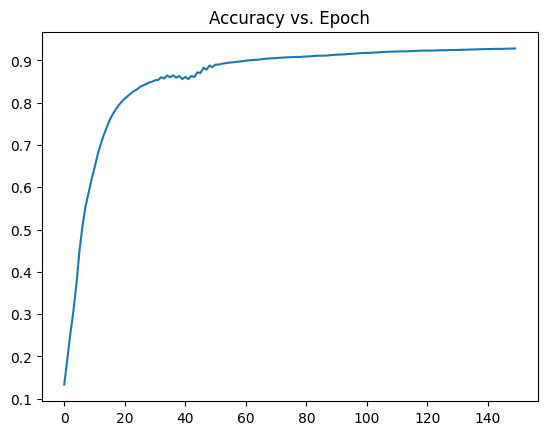

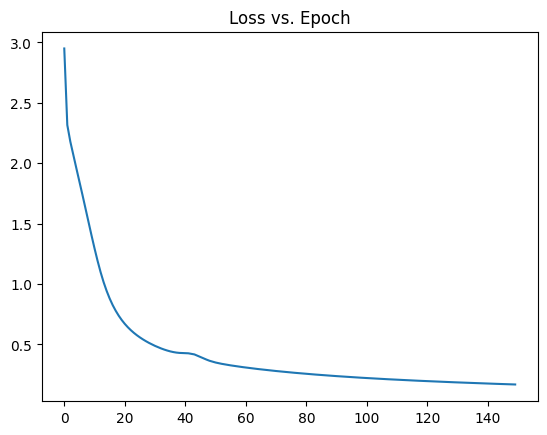

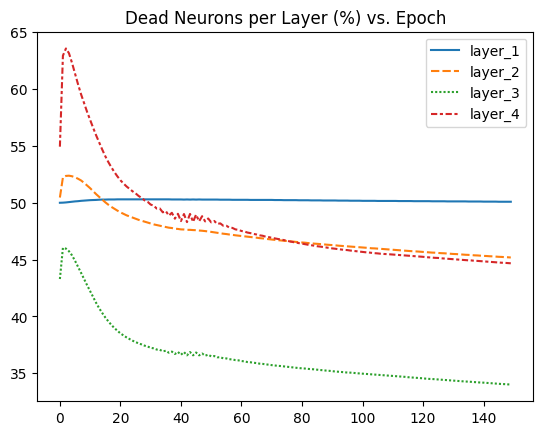

In [57]:
leaky_relu_model_plot = Plot(leaky_relu_model)
leaky_relu_model_plot.plot_all()

# Iris (Flower) Classification

## Iris Data

In [17]:
full_iris_dataset = pd.read_csv("Data/full_iris_dataset")
data = full_iris_dataset
df_data = full_iris_dataset[full_iris_dataset.columns[:4]]
df_target = pd.DataFrame(full_iris_dataset[full_iris_dataset.columns[4]])
df_data.head(5)

,sepal length,sepal width,petal length,petal width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [18]:
df_target.head(5)

,class
0,Iris-setosa
1,Iris-setosa
2,Iris-setosa
3,Iris-setosa
4,Iris-setosa


In [19]:
print (df_data.shape)
print (df_target.shape)

(150, 4)
(150, 1)


### class --> number encoding
"Iris-setosa": 0

"Iris-versicolor": 1

"Iris-virginica": 2

In [21]:
# data_encoded = data.copy()
# data_encoded["class"] = data_encoded["class"].map({"Iris-setosa": 0, "Iris-versicolor": 1, "Iris-virginica": 2})
# data_encoded.head(5)

data["class"] = data["class"].map({"Iris-setosa": 0, "Iris-versicolor": 1, "Iris-virginica": 2})
display(data.head(5))
data_encoded = data.copy()
display(data_encoded.head(5))
data_encoded = data_encoded.to_numpy()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
# data_encoded = data_encoded.to_numpy()

print (data_encoded.shape)

np.random.seed(42)
np.random.shuffle(data_encoded)

(150, 5)


In [6]:
train = data_encoded[:int(0.8*(data_encoded.shape[0]))].T
test = data_encoded[int(0.8*(data_encoded.shape[0])):].T
# print ("0", train[0])
# print ("1", train[1])
# print ("2", train[2])
# print ("3", train[3])
# print ("4", train[4])
# print ("len", len(train[3]))

X_train, Y_train = train[:4], train[4]
X_test, Y_test = test[:4], test[4]

print ("X_train\n", X_train)
print ("Y_train\n", Y_train)
print ("X_test\n", X_test)
print ("Y_test\n", Y_test)

X_train
 [[6.1 5.7 7.7 6.  6.8 5.4 5.6 6.9 6.2 5.8 6.5 4.8 5.5 4.9 5.1 6.3 6.5 5.6
  5.7 6.4 4.7 6.1 5.  6.4 7.9 6.7 6.7 6.8 4.8 4.8 4.6 5.7 6.7 4.8 4.4 6.3
  6.4 5.2 5.  5.2 5.8 6.  6.7 5.4 5.4 5.5 6.3 6.4 6.6 7.2 5.7 7.6 5.6 5.1
  7.7 5.8 5.2 5.  5.1 5.  6.3 4.8 5.  5.1 5.6 5.1 5.7 7.7 4.6 6.2 5.7 5.5
  6.  5.8 6.  5.4 6.2 5.5 5.4 5.  6.4 5.  5.  5.5 6.7 4.9 5.8 5.  5.  5.9
  5.1 6.9 6.  6.1 7.7 5.5 4.4 4.3 6.  7.2 4.6 5.1 4.4 6.3 6.3 4.6 6.8 6.3
  4.7 6.1 6.5 6.2 7.  6.4 5.1 6.9 5.9 6.5 5.7 5.2]
 [2.8 3.8 2.6 2.9 2.8 3.4 2.9 3.1 2.2 2.7 3.2 3.  3.5 3.1 3.8 3.3 3.  2.5
  2.8 2.8 3.2 3.  3.4 2.8 3.8 3.  2.5 3.2 3.  3.1 3.6 4.4 3.1 3.4 3.2 2.5
  3.2 3.5 3.6 4.1 2.7 3.4 3.1 3.9 3.7 2.4 2.8 3.1 3.  3.6 2.9 3.  3.  3.5
  2.8 2.7 3.4 3.5 3.8 2.  2.7 3.4 3.  3.3 2.7 3.4 3.  3.8 3.2 2.9 2.5 4.2
  3.  2.7 2.2 3.  3.4 2.3 3.9 2.3 2.7 3.3 3.2 2.4 3.  3.1 2.8 3.4 3.5 3.2
  2.5 3.2 2.7 2.6 3.  2.5 2.9 3.  2.2 3.2 3.1 3.5 3.  2.5 3.4 3.4 3.  3.3
  3.2 2.9 2.8 2.8 3.2 3.2 3.8 3.1 3.  3.  2.6 2.7]
 

## Running on Iris

In [8]:
test_iris = NN(X_train=X_train, Y_train=Y_train, X_test=X_test, Y_test=Y_test, hidden_layer_sizes=np.array([5, 5]))
# print ("initialized")

Initializing Network



In [9]:
test_iris.train(epochs=75, learning_rate=0.05)
print ("trained")

---------------------------------
epoch: 0
accuracy: 0.36666666666666664
---------------------------------
epoch: 10
accuracy: 0.6
---------------------------------
epoch: 20
accuracy: 0.6
---------------------------------
epoch: 30
accuracy: 0.6
---------------------------------
epoch: 40
accuracy: 0.6
---------------------------------
epoch: 50
accuracy: 0.6
---------------------------------
epoch: 60
accuracy: 0.7
---------------------------------
epoch: 70
accuracy: 0.8333333333333334


 Highest Accuracy:
	Epoch # = 74
	Accuracy = 0.9666666666666667
trained


In [11]:
test_iris.predict()

np.float64(0.9666666666666667)